# Notebook 3 — FAISS and Fast Indexes

Notebook 1 showed that a brute-force search gets slower with every vector you add.
Notebook 2 mentioned that Chroma avoids this with an **HNSW** index. This notebook opens
that box. You will build four kinds of indexes with **FAISS**, a fast open-source library
for vector search, and measure on 20,000 real embeddings what each one gains in speed and
loses in accuracy.

**What you will learn**

1. How to measure an approximate search: **recall@k**.
2. The exact baseline: a Flat index.
3. IVF: search only the nearest clusters.
4. HNSW: walk a graph of neighbors.
5. LSH: compare short bit codes.
6. How the speed difference grows with the collection, and how to choose and save an index.

**Before you start**

```bash
ollama pull nomic-embed-text   # embedding model; no chat model needed here
uv sync
```

The first run downloads an open dataset (about 35 MB) and embeds 20,000 questions, which
takes about 3 minutes on our machine. Both are saved in `.cache/`, so later runs take
seconds. Choose the `.venv` Python kernel for this notebook. ⏱️ About 40 minutes.

## 1. Setup

In [1]:
import json
import time
import urllib.request
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np

from roadmap import get_client, get_settings

settings = get_settings()
CACHE = Path(".cache")  # listed in .gitignore
ASSETS = Path("assets")
CACHE.mkdir(exist_ok=True)
ASSETS.mkdir(exist_ok=True)
print("faiss", faiss.__version__)

faiss 1.16.0


## 2. The data: 20,000 real questions

To compare indexes we need many real embeddings. We use **SQuAD v1.1**, an open dataset
of questions that people wrote about Wikipedia articles (license: CC BY-SA 4.0). The
questions cover hundreds of topics, from Beyoncé to chloroplasts, which makes them a good
test for a search.

- **Collection:** 20,000 questions from the training set, picked at random.
- **Queries:** 500 questions from the separate development set, so no query is in the
  collection.

In [2]:
SQUAD_URL = "https://rajpurkar.github.io/SQuAD-explorer/dataset/"


def squad_questions(file_name: str) -> list[str]:
    """Download a SQuAD file once, then return its unique questions in a fixed order."""
    path = CACHE / file_name
    if not path.exists():
        urllib.request.urlretrieve(SQUAD_URL + file_name, path)
    data = json.loads(path.read_text(encoding="utf-8"))["data"]
    questions = {
        qa["question"].strip()
        for article in data
        for paragraph in article["paragraphs"]
        for qa in paragraph["qas"]
    }
    return sorted(questions)


rng = np.random.default_rng(0)  # a fixed seed, so every run picks the same questions
train, dev = squad_questions("train-v1.1.json"), squad_questions("dev-v1.1.json")
texts = [train[i] for i in sorted(rng.choice(len(train), 20_000, replace=False))]
query_texts = [dev[i] for i in sorted(rng.choice(len(dev), 500, replace=False))]

print(f"{len(train):,} training questions -> collection of {len(texts):,}")
print(f"{len(dev):,} development questions -> {len(query_texts)} queries\n")
for text in texts[:3]:
    print(" ", text)

87,342 training questions -> collection of 20,000
10,533 development questions -> 500 queries

  "Charlie's Angels" featured which single from the band members?
  "Jesus Walks" was on which of Kanye's albums?
  "Nederduits" often caused people to mix up the language of the Netherlands with that spoken in what directional area of Germany?


Now the embeddings. Ollama can embed many texts in one request; we send 128 at a time,
because much bigger requests made Ollama fail in our tests. The vectors are saved, so this
only runs once.

In [3]:
def embed(texts: list[str], batch_size: int = 128) -> np.ndarray:
    client = get_client()
    vectors = []
    for start in range(0, len(texts), batch_size):
        response = client.embed(model=settings.embed_model, input=texts[start : start + batch_size])
        vectors.extend(response.embeddings)
    return np.array(vectors, dtype=np.float32)  # FAISS works with 32-bit floats


def cached_embeddings(name: str, texts: list[str]) -> np.ndarray:
    path = CACHE / f"{name}.npy"
    if path.exists():
        return np.load(path)
    start = time.perf_counter()
    vectors = embed(texts)
    print(f"Embedded {len(texts):,} texts in {time.perf_counter() - start:.0f} s")
    np.save(path, vectors)
    return vectors


vectors = cached_embeddings("squad_collection_20k", texts)
query_vectors = cached_embeddings("squad_queries_500", query_texts)
print("Collection:", vectors.shape, "| queries:", query_vectors.shape)
print("Lengths:", np.round(np.linalg.norm(vectors[:3], axis=1), 3))

Embedded 20,000 texts in 171 s


Embedded 500 texts in 5 s
Collection: (20000, 768) | queries: (500, 768)
Lengths: [1. 1. 1.]


The vectors are normalized again (length 1), so the inner product (dot product) is the
cosine similarity, as in Notebook 1.

## 3. Flat: the exact baseline

![Four ways to find the nearest vectors](assets/ann_indexes.svg)

A FAISS **index** stores vectors and searches them. The simplest one, `IndexFlatIP`, is the
brute-force search from Notebook 1: it compares the query with every vector by inner
product (IP). `search()` takes a batch of query vectors and returns two arrays: the scores,
and the positions of the best vectors in the order you added them. Use the positions to
look up your own texts.

In [4]:
DIM = vectors.shape[1]  # 768
K = 10  # how many neighbors we ask for

flat = faiss.IndexFlatIP(DIM)
flat.add(vectors)
print(f"Flat index: {flat.ntotal:,} vectors\n")

query = "How long did Western Europe control Cyprus?"
query_vector = embed([query])
scores, positions = flat.search(query_vector, 3)
print(query)
for score, position in zip(scores[0], positions[0], strict=True):
    print(f"   {score:.3f}  {texts[position]}")

Flat index: 20,000 vectors

How long did Western Europe control Cyprus?
   0.744  Which empire frequently raided Cyprus during Venetian rule?
   0.744  In what years was Cyprus divided?
   0.740  Initially Turkish Cypriots favoured the continued rule of what Western power?


The closest questions are about Cyprus and its rulers, though they share few words with
the query.

Now let's time the exact search for all 500 queries, one query at a time, the way an app
answers its users. The results also become our **ground truth**: the true 10 nearest
neighbors of every query.

In [5]:
def timed_search(index) -> tuple[np.ndarray, float]:
    """Search the 500 queries one by one. Returns the found positions and ms per query."""
    start = time.perf_counter()
    found = np.vstack(
        [index.search(query_vectors[i : i + 1], K)[1] for i in range(len(query_vectors))]
    )
    return found, (time.perf_counter() - start) / len(query_vectors) * 1000


true_neighbors, flat_ms = timed_search(flat)
print(f"Flat: {flat_ms:.3f} ms per query")

Flat: 0.932 ms per query


## 4. Recall@k: how good is an approximate search?

The other indexes are **approximate**: to be faster, they skip most of the vectors, so
they can miss some of the true neighbors. We measure how many they find:

> **Recall@k:** of the true k nearest neighbors, the share that the index returns.
> Recall@10 = 0.9 means that, on average, 9 of the true top 10 were found.

The Flat index has a recall of 1.0 by definition. Every result in this notebook is
measured against it.

In [6]:
def recall_at_k(found: np.ndarray) -> float:
    hits = [len(set(f) & set(t)) for f, t in zip(found, true_neighbors, strict=True)]
    return float(np.mean(hits)) / K


def size_mb(index) -> float:
    """How much memory the index needs, measured by saving it to bytes."""
    return faiss.serialize_index(index).nbytes / 1e6


results = {"Flat": [(flat_ms, recall_at_k(true_neighbors))]}
print(f"Flat: recall@10 {recall_at_k(true_neighbors):.2f}, {size_mb(flat):.0f} MB")

Flat: recall@10 1.00, 61 MB


## 5. IVF: search only the nearest clusters

**IVF** (inverted file index) first groups the vectors into clusters with **k-means**:
it finds `nlist` cluster centers and puts every vector into the list of its nearest
center. This grouping is called **training**, and it runs once, before the vectors are
added. A search then compares the query with the centers and only looks inside the
`nprobe` closest clusters.

| Setting | Meaning | Bigger means |
|---|---|---|
| `nlist` | number of clusters | smaller clusters, faster but riskier searches |
| `nprobe` | clusters searched per query | higher recall, slower |

A common start for `nlist` is the square root of the collection size.

In [7]:
nlist = int(np.sqrt(len(vectors)))  # 141 clusters for 20,000 vectors
quantizer = faiss.IndexFlatIP(DIM)  # finds the nearest cluster centers
ivf = faiss.IndexIVFFlat(quantizer, DIM, nlist, faiss.METRIC_INNER_PRODUCT)

start = time.perf_counter()
ivf.train(vectors)  # k-means: find the cluster centers
ivf.add(vectors)  # put every vector into its cluster
print(f"IVF with {nlist} clusters built in {time.perf_counter() - start:.2f} s\n")

results["IVF"] = []
for nprobe in (1, 2, 4, 8, 16, 32, 64):
    ivf.nprobe = nprobe
    found, ms = timed_search(ivf)
    results["IVF"].append((ms, recall_at_k(found)))
    print(f"nprobe {nprobe:>3}: {ms:.3f} ms per query, recall@10 {recall_at_k(found):.2f}")

IVF with 141 clusters built in 0.10 s

nprobe   1: 0.026 ms per query, recall@10 0.34
nprobe   2: 0.036 ms per query, recall@10 0.48
nprobe   4: 0.057 ms per query, recall@10 0.61


nprobe   8: 0.101 ms per query, recall@10 0.73


nprobe  16: 0.187 ms per query, recall@10 0.83


nprobe  32: 0.353 ms per query, recall@10 0.91


nprobe  64: 0.666 ms per query, recall@10 0.97


**What to notice:** with one cluster, the search is very fast but finds only about a third
of the true neighbors: many of them sit in a neighboring cluster. Each step up in `nprobe`
finds more of them and costs more time. At `nprobe` 64 the index searches almost half of
all clusters, and it is barely faster than Flat.

## 6. HNSW: walk a graph of neighbors

**HNSW** (Hierarchical Navigable Small World) links every vector to some of its nearest
neighbors, which makes a graph. It builds several layers: the top layer has only a few
vectors with long links, the bottom layer has all of them. A search starts at the top,
jumps close to the query in a few long steps, then walks down and keeps stepping to closer
neighbors.

| Setting | Meaning | Bigger means |
|---|---|---|
| `M` | links per vector | higher recall, more memory, slower build |
| `efSearch` | candidates kept during a search | higher recall, slower search |

HNSW needs no training. It is the index Chroma uses (Notebook 2), with 16 links per vector
by default.

In [8]:
for links in (16, 32):
    hnsw = faiss.IndexHNSWFlat(DIM, links, faiss.METRIC_INNER_PRODUCT)
    start = time.perf_counter()
    hnsw.add(vectors)  # builds the graph while adding
    print(
        f"HNSW with M={links} built in {time.perf_counter() - start:.2f} s, {size_mb(hnsw):.0f} MB"
    )

    results[f"HNSW M={links}"] = []
    for ef in (8, 16, 32, 64, 128, 256):
        hnsw.hnsw.efSearch = ef
        found, ms = timed_search(hnsw)
        results[f"HNSW M={links}"].append((ms, recall_at_k(found)))
        print(f"   efSearch {ef:>3}: {ms:.3f} ms per query, recall@10 {recall_at_k(found):.2f}")

HNSW with M=16 built in 0.59 s, 64 MB
   efSearch   8: 0.043 ms per query, recall@10 0.65
   efSearch  16: 0.059 ms per query, recall@10 0.78
   efSearch  32: 0.093 ms per query, recall@10 0.89
   efSearch  64: 0.163 ms per query, recall@10 0.95


   efSearch 128: 0.283 ms per query, recall@10 0.98


   efSearch 256: 0.527 ms per query, recall@10 0.99


HNSW with M=32 built in 0.92 s, 67 MB
   efSearch   8: 0.064 ms per query, recall@10 0.79
   efSearch  16: 0.097 ms per query, recall@10 0.89
   efSearch  32: 0.154 ms per query, recall@10 0.95


   efSearch  64: 0.246 ms per query, recall@10 0.98


   efSearch 128: 0.433 ms per query, recall@10 0.99


   efSearch 256: 0.783 ms per query, recall@10 1.00


**What to notice:**

- HNSW reaches a recall of about 0.95 while being several times faster than Flat.
- `M=32` finds more neighbors than `M=16` at the same `efSearch`, but takes longer to
  build and needs more memory for the links.
- The index is bigger than Flat: it stores all the vectors **plus** the graph.

## 7. LSH: compare short bit codes

**LSH** (locality-sensitive hashing) draws `nbits` random planes through the space. For
each plane, a vector gets a 1 if it lies on one side and a 0 if it lies on the other. The
result is a short code of bits. Close vectors tend to get similar codes, so the search
compares codes (by counting the bits that differ, the **Hamming distance**) instead of
768 numbers.

In [9]:
results["LSH"] = []
for nbits in (128, 256, 512, 1024, 2048):
    lsh = faiss.IndexLSH(DIM, nbits)
    lsh.add(vectors)
    found, ms = timed_search(lsh)
    recall = recall_at_k(found)
    results["LSH"].append((ms, recall))
    print(f"{nbits:>5} bits: {ms:.3f} ms per query, recall@10 {recall:.2f}, {size_mb(lsh):4.1f} MB")

  128 bits: 0.173 ms per query, recall@10 0.10,  0.7 MB


  256 bits: 0.182 ms per query, recall@10 0.22,  1.4 MB


  512 bits: 0.185 ms per query, recall@10 0.41,  2.9 MB


 1024 bits: 0.242 ms per query, recall@10 0.56,  5.7 MB


 2048 bits: 0.403 ms per query, recall@10 0.68, 11.4 MB


**What to notice:** the codes are small. 128 bits per vector need about 1% of Flat's memory,
and even 2,048 bits need less than a fifth. But the recall stays low: random planes lose too much of the detail in
768-dimensional embeddings. LSH works better for other jobs, such as finding near-duplicate
documents, and when memory matters more than accuracy.

## 8. Speed vs. recall

Here is every setting from sections 3 to 7 in one chart. The best place is the top left:
high recall, little time.

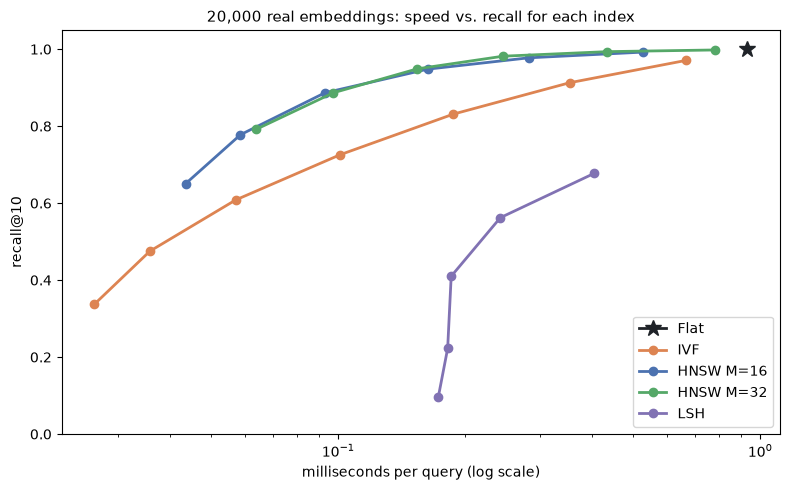

In [10]:
styles = {
    "Flat": ("#1f2328", "*"),
    "IVF": ("#DD8452", "o"),
    "HNSW M=16": ("#4C72B0", "o"),
    "HNSW M=32": ("#55A868", "o"),
    "LSH": ("#8172B3", "o"),
}
fig, ax = plt.subplots(figsize=(8, 5))
for name, points in results.items():
    color, marker = styles[name]
    ms, recall = zip(*points, strict=True)
    ax.plot(
        ms,
        recall,
        marker=marker,
        markersize=12 if marker == "*" else 6,
        color=color,
        linewidth=2,
        label=name,
    )
ax.set_xscale("log")
ax.set_xlabel("milliseconds per query (log scale)")
ax.set_ylabel("recall@10")
ax.set_ylim(0, 1.05)
ax.set_title("20,000 real embeddings: speed vs. recall for each index", fontsize=11)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(ASSETS / "ann_tradeoff.png", dpi=120)
plt.show()

The HNSW curves lie highest: for any recall above 0.8, they need the least time. IVF
follows, and LSH stays far below. The two HNSW curves almost overlap: for the same recall,
`M=16` with a higher `efSearch` is as fast as `M=32`, and its graph is smaller.

## 9. Bigger collections, bigger gap

With 20,000 vectors, Flat still answers in under a millisecond, so the gain looks small.
Notebook 1 showed that Flat grows in a straight line with the collection. HNSW grows much
more slowly, because a search only visits a small part of the graph. To see this without
embedding hundreds of thousands of texts, we use random vectors. They are fine for timing,
but not for recall: random vectors have no structure, so their recall says nothing about
real data.

 25,000 vectors: Flat 1.29 ms, HNSW 0.32 ms per query (4x faster), HNSW build 1.5 s


 50,000 vectors: Flat 2.29 ms, HNSW 0.39 ms per query (6x faster), HNSW build 3.5 s


100,000 vectors: Flat 4.52 ms, HNSW 0.40 ms per query (11x faster), HNSW build 7.6 s


200,000 vectors: Flat 8.83 ms, HNSW 0.44 ms per query (20x faster), HNSW build 15.6 s


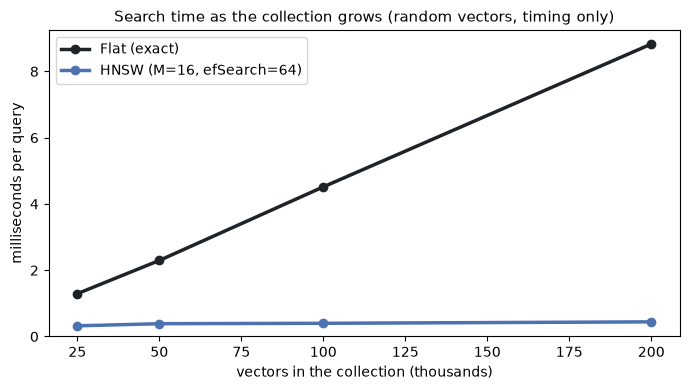

In [11]:
random_vectors = rng.standard_normal((200_000, DIM), dtype=np.float32)
random_vectors /= np.linalg.norm(random_vectors, axis=1, keepdims=True)
random_queries = rng.standard_normal((200, DIM), dtype=np.float32)
random_queries /= np.linalg.norm(random_queries, axis=1, keepdims=True)

sizes, flat_times, hnsw_times = [25_000, 50_000, 100_000, 200_000], [], []
for n in sizes:
    flat_n = faiss.IndexFlatIP(DIM)
    flat_n.add(random_vectors[:n])
    hnsw_n = faiss.IndexHNSWFlat(DIM, 16, faiss.METRIC_INNER_PRODUCT)
    start = time.perf_counter()
    hnsw_n.add(random_vectors[:n])
    build_s = time.perf_counter() - start
    hnsw_n.hnsw.efSearch = 64

    times = []
    for index in (flat_n, hnsw_n):
        start = time.perf_counter()
        for i in range(len(random_queries)):
            index.search(random_queries[i : i + 1], K)
        times.append((time.perf_counter() - start) / len(random_queries) * 1000)
    flat_times.append(times[0])
    hnsw_times.append(times[1])
    print(
        f"{n:>7,} vectors: Flat {times[0]:.2f} ms, HNSW {times[1]:.2f} ms per query "
        f"({times[0] / times[1]:.0f}x faster), HNSW build {build_s:.1f} s"
    )

fig, ax = plt.subplots(figsize=(7, 4))
thousands = [n / 1000 for n in sizes]
ax.plot(thousands, flat_times, marker="o", color="#1f2328", linewidth=2.5, label="Flat (exact)")
ax.plot(
    thousands,
    hnsw_times,
    marker="o",
    color="#4C72B0",
    linewidth=2.5,
    label="HNSW (M=16, efSearch=64)",
)
ax.set_xlabel("vectors in the collection (thousands)")
ax.set_ylabel("milliseconds per query")
ax.set_ylim(bottom=0)
ax.set_title("Search time as the collection grows (random vectors, timing only)", fontsize=11)
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "ann_scaling.png", dpi=120)
plt.show()

Flat's time doubles with every doubling of the collection, while HNSW stays almost flat.
The gap keeps growing: at millions of vectors, an approximate index is no longer optional.
The price is paid at build time, which grows too.

## 10. Choosing and saving an index

| Index | Recall | Speed | Memory | Good for |
|---|---|---|---|---|
| **Flat** | exact | slow for big collections | vectors only | up to about 100,000 vectors, or when results must be exact |
| **IVF** | tunable with `nprobe` | fast | vectors + centers | large collections; needs training data like the real data |
| **HNSW** | high | very fast | vectors + graph (more) | most apps; the default of many vector databases |
| **LSH** | low for embeddings | medium | tiny | near-duplicate detection, very low memory |

Three rules of thumb:

- Start with Flat. Switch when searches get too slow, not before.
- For most apps the next step is HNSW. Tune `efSearch` until the recall is good enough.
- Measure recall@k on **your** data with a few hundred real queries, as in this notebook.
  Numbers from other datasets do not transfer.

Building an index takes time, so save it. A FAISS index is saved to one file and loaded in
milliseconds. It stores only vectors and positions, so save your texts next to it:

In [12]:
best = faiss.IndexHNSWFlat(DIM, 32, faiss.METRIC_INNER_PRODUCT)
best.add(vectors)
best.hnsw.efSearch = 64
faiss.write_index(best, str(CACHE / "squad_hnsw.index"))
(CACHE / "squad_texts.json").write_text(json.dumps(texts), encoding="utf-8")

start = time.perf_counter()
loaded = faiss.read_index(str(CACHE / "squad_hnsw.index"))
loaded_texts = json.loads((CACHE / "squad_texts.json").read_text(encoding="utf-8"))
print(f"Loaded {loaded.ntotal:,} vectors in {(time.perf_counter() - start) * 1000:.0f} ms")
print(f"efSearch after loading: {loaded.hnsw.efSearch}\n")

scores, positions = loaded.search(embed(["Which satellites did Nigeria launch?"]), 3)
for score, position in zip(scores[0], positions[0], strict=True):
    print(f"   {score:.3f}  {loaded_texts[position]}")

Loaded 20,000 vectors in 16 ms
efSearch after loading: 64

   0.883  where was Nigeria's third satellite launched?
   0.860  When was Nigeria's third satellite launched?
   0.824  What was Nigeria's fourth satellite called?


The file keeps the search settings too: `efSearch` is still 64 after loading (a new HNSW
index starts at 16). The same holds for `nprobe` in an IVF index.

## 11. Summary

| Idea | What it means | In code |
|---|---|---|
| Recall@k | Share of the true top k that an index finds | compare with a Flat search |
| Flat | Exact search over every vector | `faiss.IndexFlatIP(dim)` |
| IVF | k-means clusters; search the `nprobe` nearest ones | `faiss.IndexIVFFlat(quantizer, dim, nlist, metric)`, `train()`, `nprobe` |
| HNSW | Layered graph of neighbors; no training | `faiss.IndexHNSWFlat(dim, M, metric)`, `hnsw.efSearch` |
| LSH | Random planes turn vectors into bit codes | `faiss.IndexLSH(dim, nbits)` |
| Save and load | One file per index; keep your texts next to it | `faiss.write_index`, `faiss.read_index` |

**Remember:** an approximate index trades a little recall for a lot of speed, and the
trade gets better as the collection grows. Measure both on your own data.

This is the end of the Stage 3 notebooks. Next, the Stage 3 projects put these ideas into
small apps.